In [1]:
# ===== 0) Imports & setup =====
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
import joblib


2025-09-02 22:32:10.997725: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756852331.355137      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756852331.454689      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
import warnings
warnings.filterwarnings("ignore")  # Ignore all warnings

In [3]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# ===== 1) Load / prepare dataframe =====
import pandas as pd

# Step 1: Load dataset
df = pd.read_csv("/kaggle/input/peshawar-data-from-the-2019-to-72025/Peshawar Weather data 1january2019-endofjuly2025(in).csv")


# ['datetime','tmax','tmin','tavg','dew_point','humidity','precip','wspd','pressure']

In [5]:
# Ensure sorted by time & clean
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)
df = df.dropna(subset=['tavg','humidity','wspd','precip','pressure','dew_point'])

In [6]:
# Define features
input_features  = ['pressure', 'dew_point', 'humidity', 'wspd', 'tavg']  # no precip in inputs
target_features = ['tavg', 'humidity', 'wspd', 'precip']                 # 4 targets

X_raw = df[input_features].values.astype('float32')
y_raw = df[target_features].values.astype('float32')

In [7]:
# OPTIONAL: stabilize precipitation (helps if many zeros / tiny values)
# Comment out if you don't want it.
use_log_precip = True
if use_log_precip:
    # y[:, -1] corresponds to 'precip'
    y_raw[:, -1] = np.log1p(y_raw[:, -1])

In [8]:
# ===== 2) Scale inputs & outputs (separate scalers) =====
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X_raw)
y_scaled = scaler_y.fit_transform(y_raw)

# Save scalers
joblib.dump(scaler_X, "scaler_X.pkl")
joblib.dump(scaler_y, "scaler_y.pkl")

['scaler_y.pkl']

In [9]:
# ===== 3) Create sequences (next-step forecasting) =====
def make_sequences(X, y, window_size=30):
    Xs, ys = [], []
    for i in range(len(X) - window_size):
        Xs.append(X[i:i+window_size])
        ys.append(y[i+window_size])  # predict t+1
    return np.array(Xs), np.array(ys)

window_size = 30  # good starting point for daily data
X_seq, y_seq = make_sequences(X_scaled, y_scaled, window_size)

n_samples, n_steps, n_features = X_seq.shape  # n_features used for model input

In [10]:
# ===== 4) Time-based split: train/val/test =====
# 70% train, 15% val, 15% test (all chronological)
n_train = int(0.70 * n_samples)
n_val   = int(0.15 * n_samples)

X_train, y_train = X_seq[:n_train], y_seq[:n_train]
X_val,   y_val   = X_seq[n_train:n_train+n_val], y_seq[n_train:n_train+n_val]
X_test,  y_test  = X_seq[n_train+n_val:], y_seq[n_train+n_val:]

print("Shapes →",
      "Train:", X_train.shape, y_train.shape,
      "Val:", X_val.shape, y_val.shape,
      "Test:", X_test.shape, y_test.shape)

Shapes → Train: (1661, 30, 5) (1661, 4) Val: (356, 30, 5) (356, 4) Test: (357, 30, 5) (357, 4)


In [11]:
# ===== 5) Build a unidirectional LSTM (balanced capacity) =====
model = Sequential([
    LSTM(128, return_sequences=True, input_shape=(n_steps, n_features)),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(len(target_features), activation='linear')  # 4 outputs
])

model.compile(optimizer=Adam(learning_rate=1e-3),
              loss='mse',
              metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae')])

model.summary()

I0000 00:00:1756852349.966215      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1756852349.966954      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 128)        │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,228 (469.64 KB)

 Trainable params: 120,228 (469.64 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ===== 6) Callbacks =====
early_stop = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', patience=6, factor=0.5, verbose=1, min_lr=1e-5)
checkpoint = ModelCheckpoint("best_lstm.keras", monitor='val_loss', save_best_only=True, verbose=1)

# ===== 7) Train =====
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/150


I0000 00:00:1756852355.695642      98 cuda_dnn.cc:529] Loaded cuDNN version 90300


46/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0503 - mae: 0.1580
Epoch 1: val_loss improved from inf to 0.01140, saving model to best_lstm.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0468 - mae: 0.1514 - val_loss: 0.0114 - val_mae: 0.0721 - learning_rate: 0.0010
Epoch 2/150
48/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0110 - mae: 0.0745
Epoch 2: val_loss improved from 0.01140 to 0.01012, saving model to best_lstm.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0109 - mae: 0.0742 - val_loss: 0.0101 - val_mae: 0.0677 - learning_rate: 0.0010
Epoch 3/150
48/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0100 - mae: 0.0698
Epoch 3: val_loss improved from 0.01012 to 0.01003, saving model to best_lstm.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0099 - mae: 0.0695 - val_loss: 0.0100 - val_mae: 0.0657 - learning_rate: 0.0010
Epoch 4/150
49/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0093 - mae: 0.0674
Epoch 4: val_loss improved from 0.01003 to 0.00957, sav

In [13]:
# ===== 8) Evaluate (inverse transform per-target MAE/RMSE) =====
# Predict
y_pred_scaled = model.predict(X_test, verbose=0)

# Inverse scale
y_test_inv = scaler_y.inverse_transform(y_test)
y_pred_inv = scaler_y.inverse_transform(y_pred_scaled)

# Undo log1p for precip if used
if use_log_precip:
    # last column is precip
    y_test_inv[:, -1] = np.expm1(y_test_inv[:, -1])
    y_pred_inv[:, -1] = np.expm1(y_pred_inv[:, -1])

In [14]:
# Per-target metrics
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

names = target_features
for j, name in enumerate(names):
    mae_j  = mean_absolute_error(y_test_inv[:, j], y_pred_inv[:, j])
    rmse_j = rmse(y_test_inv[:, j], y_pred_inv[:, j])
    print(f"{name:>10s} → MAE: {mae_j:.4f} | RMSE: {rmse_j:.4f}")

# Overall MAE (average over targets)
overall_mae  = np.mean(np.abs(y_test_inv - y_pred_inv))
overall_rmse = np.sqrt(np.mean((y_test_inv - y_pred_inv)**2))
print(f"\nOverall → MAE: {overall_mae:.4f} | RMSE: {overall_rmse:.4f}")

      tavg → MAE: 2.2016 | RMSE: 2.7852
  humidity → MAE: 5.5269 | RMSE: 7.4208
      wspd → MAE: 5.3054 | RMSE: 7.9869
    precip → MAE: 0.0895 | RMSE: 0.1879

Overall → MAE: 3.2808 | RMSE: 5.6270


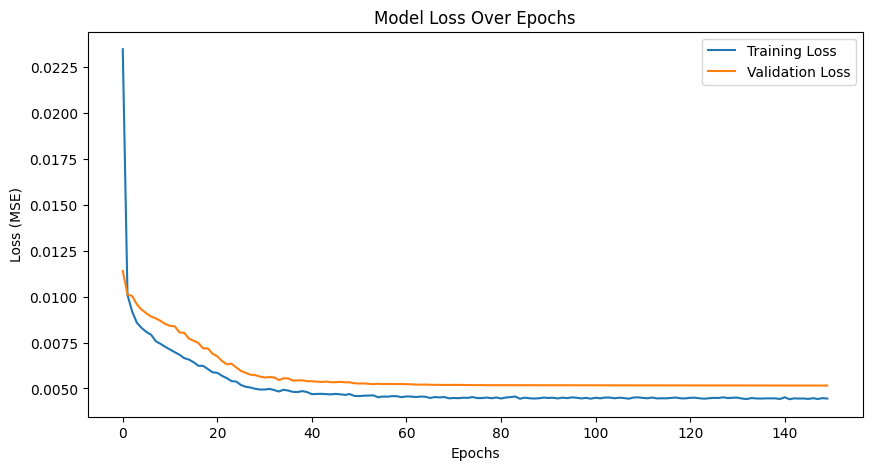

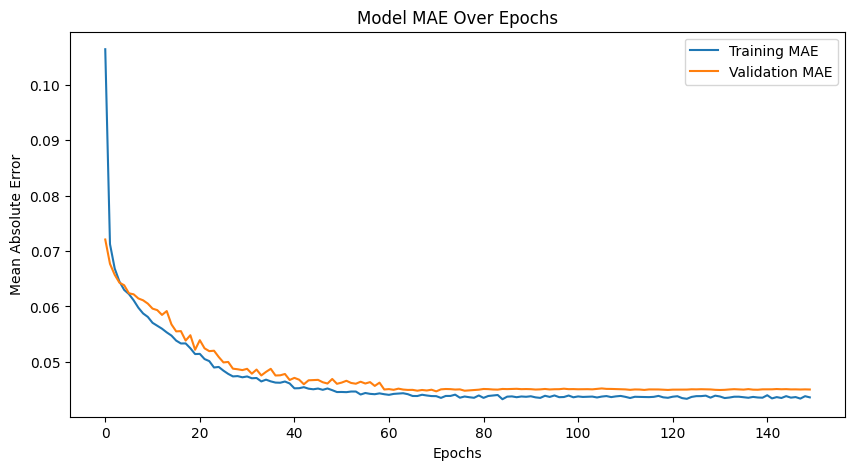

In [15]:
import matplotlib.pyplot as plt

# Assuming your model.fit() is stored like this:
# history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=32)

# Plot training & validation loss
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

# Plot training & validation MAE
plt.figure(figsize=(10,5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error')
plt.legend()
plt.show()


# GET Model Prediction

In [20]:
# Get predictions
y_pred = model.predict(X_test)

# Inverse transform (make sure both have correct shape)
y_test_inv = scaler_y.inverse_transform(y_test)   # scaler fitted on target during training
y_pred_inv = scaler_y.inverse_transform(y_pred)

# Create results DataFrame
df_results = pd.DataFrame({
    "Actual_Temp": np.round(y_test_inv[:, 0], 2),
    "Pred_Temp": np.round(y_pred_inv[:, 0], 2),
    "Actual_Humidity": np.round(y_test_inv[:, 1], 2),
    "Pred_Humidity": np.round(y_pred_inv[:, 1], 2),
    "Actual_WindSpeed": np.round(y_test_inv[:, 2], 2),
    "Pred_WindSpeed": np.round(y_pred_inv[:, 2], 2),
    "Actual_Rainfall": np.round(y_test_inv[:, 3], 2),
    "Pred_Rainfall": np.round(y_pred_inv[:, 3], 2),
})

# Show first 10 rows
print(df_results.sample(10))


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
     Actual_Temp  Pred_Temp  Actual_Humidity  Pred_Humidity  Actual_WindSpeed  \
257    82.800003  84.699997        30.900000      36.119999         11.400000   
171    57.299999  57.700001        25.000000      36.790001          6.900000   
77     73.699997  75.059998        58.599998      59.099998          6.900000   
65     76.099998  78.419998        65.699997      58.790001          6.900000   
81     73.099998  71.230003        69.699997      71.690002          6.900000   
197    56.700001  54.060001        69.099998      79.209999          9.200000   
164    56.799999  54.520000        49.900002      54.689999         18.299999   
148    57.000000  52.080002        61.299999      62.240002          4.700000   
343    88.400002  85.800003        66.400002      66.980003         13.900000   
344    91.500000  86.959999        65.800003      65.529999         11.400000   

     Pred_WindSpeed  Actual_Rainfall  Pred_Rainfall  
257           

In [17]:
model.input_shape

(None, 30, 5)

In [18]:
model.output_shape

(None, 4)